### sprott_test7

Introduced the Sprott System B and investigated the complexity measure for this toy system against Merredin data.

- Queensland Government, & Australian Bureau of Metreorology. (1996). SILO - Australian climate data from 1889 to yesterday [Data set]. In Using spatial interpolation to construct a comprehensive archive of Australian climate data. https://doi.org/10.1016/S1364-8152(01)00008-1    

-- Examined effects of changing coefficient and constant values for Sprott B System ordinary differential equations  to find parameters that best suit sample Merredin data    
-- Calculated consequent 'complexity' of the toy system at varying parameters. 

--- Date:   August 2026

In [1]:
import urllib.request
import urllib.parse
import pandas as pd
import io
import numpy as np
import matplotlib.pyplot as plt
from numpy import trapezoid
import math
from scipy.signal import argrelextrema


In [2]:
def collect_data(form,lat,lon,start,finish,username,password='apirequest'):
    """
    quering and requesting data from SILO using API
    """
    params = {'format': form,
              'lat': lat,
              'lon': lon,
              'start': start,
              'finish': finish,
              'username': username,
              'password': password
             }

    api_url = 'https://www.longpaddock.qld.gov.au/cgi-bin/silo' 
    url = api_url + '/DataDrillDataset.php?' + urllib.parse.urlencode(params)
    
    with urllib.request.urlopen(url) as remote:
        data = remote.read()
        body_str = data.decode('utf-8')
        
    return pd.read_csv(io.StringIO(body_str), skiprows=31, sep=r'\s+')


In [3]:
def clean_data(df):
    """
    converting requested dataset into usable pandas dataset
    - extracting dates in format dd/mm/yyyy
    - converting columns to numeric
    - computing cumulative growing degree days using tmin, tmax and tbase (10)
    """
    df = df.drop(index=0).reset_index(drop=True)
    df['Date2'] = pd.to_datetime(df['Date2'], format='%d/%m/%Y')

    # convert columns to numeric 
    for cols in df.columns:
        if cols != 'Date2':
            try:
                df[cols] = pd.to_numeric(df[cols])
            except (ValueError, TypeError):
                pass

    # extract year, month, day
    df['Year'] = df['Date2'].dt.year
    df['Month'] = df['Date2'].dt.month
    df['Day'] = df['Date2'].dt.day
    # apply GDD calculation
    df['T.Avg'] = (df['T.Max'] + df['T.Min']) / 2
    df['GDD'] = np.where(df['T.Avg'] >= 10, df['T.Avg'] - 10, 0)
    # find cumulative growing degree days
    df['GDD.C'] = df['GDD'].cumsum()
    
    return df

def prepare_data(df, by):
    """
    preparing rainfall and cumulative growing degree set variables 
    - perform smoothing on rainfall observations through rolling window average
    -
    - normalise rainfall observations
    - extract normalised rain and gddc vectors
    """

    clean = clean_data(df)
    # smooth rain values using rolling window average
    clean['Rain.Mean'] = clean.Rain.rolling(window=180,min_periods=1).mean()

    # if wanting to retain normal time based spacing (extracts a weekly point)
    if by == "Time":
        clean_rain = clean[['Rain.Mean']].values[::7]
        clean_gddc = clean[['GDD.C']].values[::7]
    else:
        # generate regular gdd poitns every 100 units
        clean_gddc = np.arange(0, clean.GDD.sum(), 100)
        # estimate rainfall at each of these gdd points
        clean_rain = np.interp(clean_gddc, clean["GDD.C"], clean["Rain.Mean"])

    normalised_rain = []
    min_val = min(clean_rain)
    max_val = max(clean_rain)
    diff = max_val - min_val # normalise through min-max scaling
    for x in clean_rain:
        normalised_rain.append((x - min_val) / diff)
    return np.array(normalised_rain).reshape(len(clean_gddc),1), clean_gddc.reshape(len(clean_gddc),1)



In [4]:
start_date = '19710101'
end_date = '20260327'

# Merredin (10092) - Kwinana East Port Zone
merre_data = collect_data('standard','-31.48','118.28',start_date,end_date,'email@gmail.com')
merre_rain, merre_gddc = prepare_data(merre_data, by = "")

In [5]:
class ESN:
    """
    N: number of nodes 
    d: average number of connections per node
    rho: spectral radius
    split: proportion of data to take as training  
    """
    def __init__(self, N, d, rho, input_scaling):
        self.N = N
        self.d = d
        self.rho = rho
        self.a = input_scaling


        # random, sparse, reservoir weights:
        ## connections between nodes decided by probability of d/N
        # sampling from normal distribution provides random weight values.
        Weights = np.multiply(
            np.random.binomial(size=(self.N,self.N), p=self.d/self.N, n=1),
            np.random.normal(size=(self.N,self.N)))
        
        # rescale so that rho = largest absolutel eigenvalue (maintaining echo state property)
        self.Vadj = Weights * (self.rho/np.max(np.absolute(np.linalg.eig(Weights)[0])))

        # input matrix: maps the scalar input to every node of the reservoir
        self.Vin = self.a * np.random.uniform(-1,1,size=(1, self.N))

        # bias matrix: bias added to each node's activation
        self.Vbias = np.random.uniform(-1,1,size=(1,self.N))

    def run_reservoir(self,input_data):
        """
        drive the reservoir using the input_data and return the state at every timestep
        states = (len(input_data), N)
        - comments keep track of matrix multiplications
        """
        states = np.zeros((len(input_data)+1, self.N)) # (timesteps x N)
        for i in range(1, len(input_data)+1): # start at 1 to access previous reservoir state
            states[i, :] = np.tanh(
                np.dot(states[i-1:i, :], self.Vadj) + # (1,N) x (N,N) = (1,N)
                np.dot(input_data[i-1:i], self.Vin) +  # (1,1) x (1,N) = (1,N)
                self.Vbias)
        return states[1:,:] # (timesteps x N), skip first row as it stays zero due to no input being processed. 
      

    def train(self, train_input, train_target, washout, beta=0.01):
        """
        fit the output weights
        - remove the initial washout period from the states and target 
        - compute Vout through ridge regression
        """
        train_states = self.run_reservoir(train_input)
        # removing the washout period 
        train_states = train_states[washout:,:] 
        train_target = train_target[washout:,]

        # using ridge regression to compute the output weights through training
        self.Vout = np.dot(
            np.linalg.pinv(np.dot(train_states.T,train_states) + beta*np.identity(self.N)), #(N,t) x (t,N) = (N,N) + (N,N)
                           np.dot(train_states.T, train_target)) #(N,t) x (t,1) = (N,1)
                           #Vout = (N,1)

        return self.Vout
                           

    def freerun(self, test_input, steps):
        """
        method to perform freerun prediction
        - train the reservoir computer on some testing input data 
        - following training, the readout prediction replaces the input data
        - ESN will form predictions just using previous predictions, with no new information being processed.  
        """
        readout = self.run_reservoir(test_input) 
        freerun_states = np.zeros((steps, self.N))
        freerun_states[0,:] = readout[-1,:]
        for i in range(1, steps):
            freerun_states[i, :] = np.tanh(np.dot(freerun_states[i-1:i, :],self.Vadj) + #(1,N) x (N,N) = (1,N)
                                           np.dot(np.dot(freerun_states[i-1:i], self.Vout), self.Vin) + 
                                           self.Vbias) # the prediction replaces input_data[i-1:i]
                                           
        return np.dot(freerun_states, self.Vout)
                     

    def predict(self, test_input, test_target,washout=10):
        """
        run reservoir on test data and map states to predictions
        - remove initial washout period from states and testing input
        - compute Root Mean Squared Error of predictions 
        """
        test_states = self.run_reservoir(test_input)

        # apply trained linear readout
        predictions = np.dot(test_states, self.Vout)

        return predictions, test_states
    
    def metrics(self, test_input, test_target, washout=10):
        """
        method to return computed Root Mean Squared Error (RMSE) and readout vector to plot.
        - generate predictions
        - compute RMSE 
        """
        predictions, test_states = self.predict(test_input, test_target)
        rmse = np.sqrt(((predictions[washout:,] - test_target[washout:,])**2).mean())


        return predictions, rmse, self.Vout



In [6]:
def splitting_data(rain,gddc,step):
    """
    function to split rainfall and cumulative growing degree days by step size
    80% of data for training, 20% for testing
    """
    # step to decide how far prediction goes
    train_size = int(len(rain) * 0.8)
    train_input = rain[:train_size-step]
    train_target = rain[step:train_size]
    test_input = rain[train_size:-step]
    test_input_x = gddc[train_size:-step]
    test_target = rain[train_size+step:]
    test_target_x = gddc[train_size+step:]

    return train_input, train_target, test_input, test_input_x, test_target, test_target_x

def plotting_data(x_values, test_actual, test_predictions, location, step, time):
    """
    function to plot the resulting predictions against the actual data
    - now adjusted to take in both gdd spacing and time spacing
    """
    plt.plot(x_values,test_actual, label = 'actual_values',color='blue',)
    plt.plot(x_values, test_predictions, label='predicted',color='green',alpha=0.6)
    if time == True:
        plt.xlabel('Time in Days')
        title = 'Reservoir Computer Prediction of Rainfall against Days for \n' + str(location) + ' at ' + str(step) + ' Steps'
        plt.title(title)
    else:
        plt.xlabel('Cumulative Growing Degree Days (°C Days)')
        title = 'Reservoir Computer Prediction of Rainfall against Cummulative GDD. for \n' + str(location) + ' at ' + str(step) + ' Steps'
        plt.title(title)
    plt.ylabel('Standardised Rain (mm)')
    plt.title(title)
    plt.legend(['Actual Values', 'Prediction'])
    plt.savefig(f'{location}_time={time}_step={step}')
    plt.show()


def calculate_metrics(esn, location, rain, gddc, step, washout=100):
    """
    function to generate ESN-based predictions and compute RMSE, 
    also returns readout vector to see node weightages assigned during training. 
    """
    train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
    esn.train(train_input, train_target, washout=washout)
    predictions, rmse, vout = esn.metrics(test_input, test_target)

    return rmse, vout # return only rmse and readout vector. 

def rc_for_location(esn, location, rain, gddc, step, plotting, time=False, washout=100):
    """
    function run the ESN prediction and return RMSE  with a plot if requested.
    """
    train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
    esn.train(train_input, train_target, washout=washout)
    rain_pred, rmse = esn.predict(test_input, test_target)
    if plotting == True:
        plotting_data(test_target_x[10:], test_target[10:], rain_pred[10:], location=location, step=step, time=time)

    return rmse


def rc_with_freerun(esn, location, rain, gddc, step, freerun_steps, time=False):
   train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
   esn.train(train_input, train_target, washout=100)
   free_run_test = esn.freerun(train_target, freerun_steps)

   plt.plot(test_input[:freerun_steps], label = 'actual_values',color='blue',)
   plt.plot(free_run_test, label='predicted',color='green',alpha=0.6)
   if time == True:
       plt.xlabel('Time in days')
       plt.title(f'Freerun Prediction of Rainfall against days at Step {freerun_steps} for Merredin')
   else:
       plt.xlabel('Cumulative Growing Degree Days (°C Days)')
       plt.title(f'Freerun Prediction of Rainfall against Cumulative Growing Degree Days\n at Step {freerun_steps} for Merredin')

   plt.ylabel('Standardised Rain (mm)')
   plt.legend(['Actual Values', 'Freerun Prediction'])
   plt.show()

   return free_run_test

## Sprott Attractor B visualisations

In [7]:
np.random.seed(123)

esn = ESN(300,10,0.9,1.0)

def sprott_attractor(matrix, coef, constant):
    """
    sprott attractor B ordinary differential equations

    will vary coef (dxdt) and constant (dzdt)
    """
    x,y,z = matrix
    dxdt = coef*y*z
    dydt = x - y 
    dzdt = constant - x*y
    return np.array([dxdt, dydt, dzdt])

def rk4_sprott(x0, y0, z0, t0, tf, h, coef, constant):
    """
    4th order runge-kutta solver
    
    param x,y,z,0: initial value
    param t0: initial time
    param tf: final time
    param h: step size
    coef: coefficient value for dxdt
    constant: constant for dzdt
    """

    n = int((tf-t0)/h)
    original = np.array([x0,y0,z0])


    vals = [original] #list of all resulting values

    for i in range(n):

        k1 = sprott_attractor(original, coef, constant) * h
        k2 = sprott_attractor(original + k1/2,coef, constant) * h
        k3 = sprott_attractor(original + k2/2, coef, constant) * h
        k4 = sprott_attractor(original + k3, coef, constant) * h

        original = original + ((1/6)*(k1+2*k2+2*k3+k4))

        vals.append(original.copy())

    return np.array(vals)



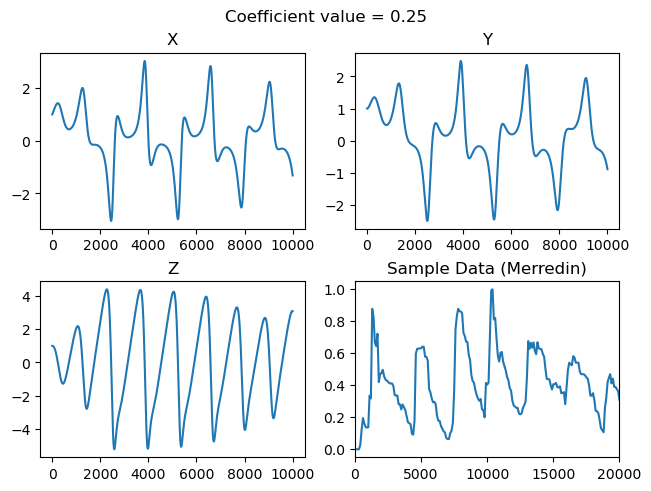

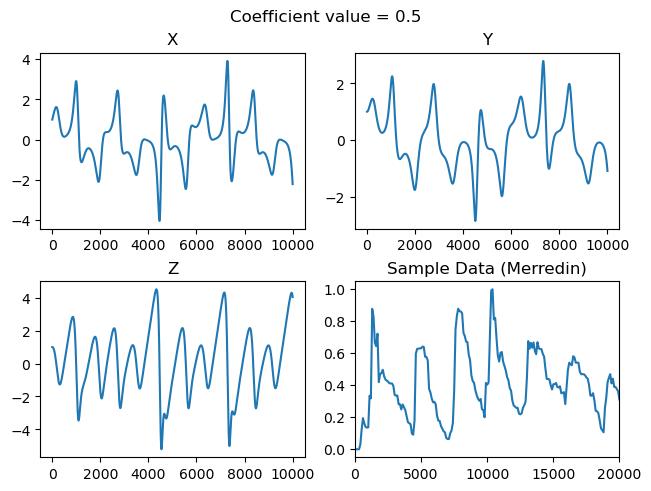

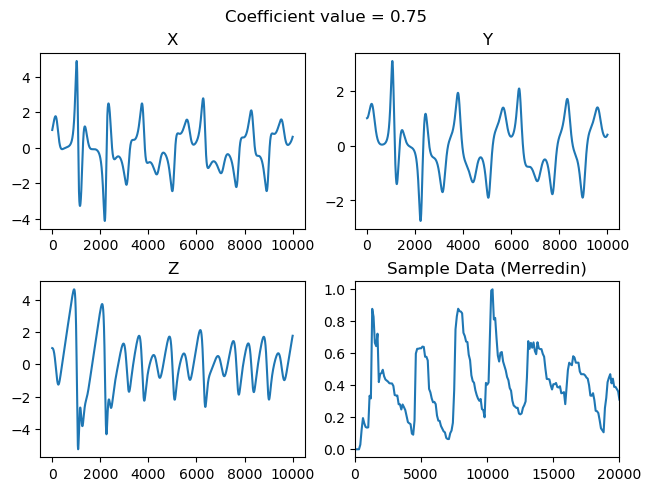

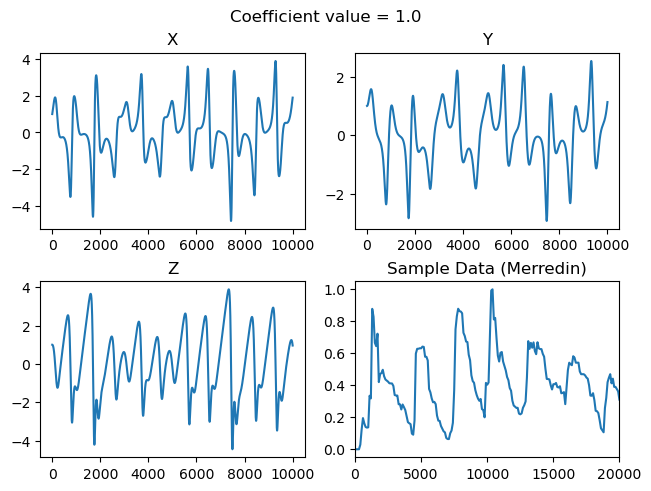

In [8]:
 # varying coefficient value for dxdt

for i in np.arange(0.25,1.01, 0.25):
    vals = rk4_sprott(x0=1, y0=1, z0=1,t0=0, tf=100,h=0.01, coef=i, constant=1)
    x,y,z = vals.T
    fig, axs = plt.subplots(2,2, layout="constrained")
    fig.suptitle(f"Coefficient value = {i}")
    axs[0,0].plot(x)
    axs[0,0].set_title('X')
    axs[0,1].plot(y)
    axs[0,1].set_title('Y')
    axs[1,0].plot(z)
    axs[1,0].set_title('Z')
    axs[1,1].plot(merre_gddc, merre_rain)
    axs[1,1].set_xlim([0,20000])
    axs[1,1].set_title('Sample Data (Merredin)')

# smaller coefficient values means more consistent patterns and lower frequency of oscillations.  

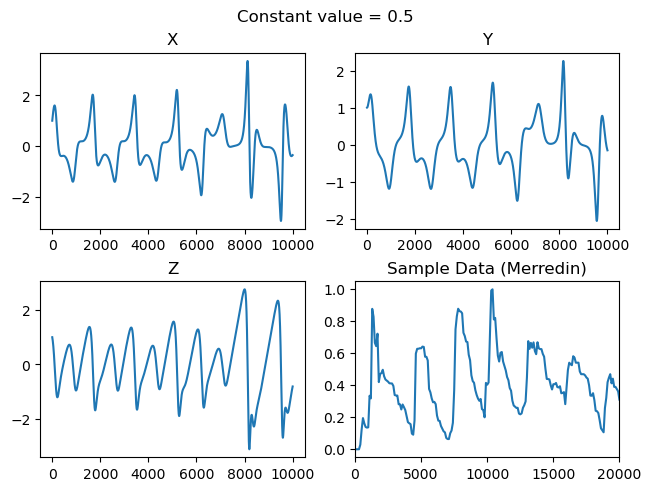

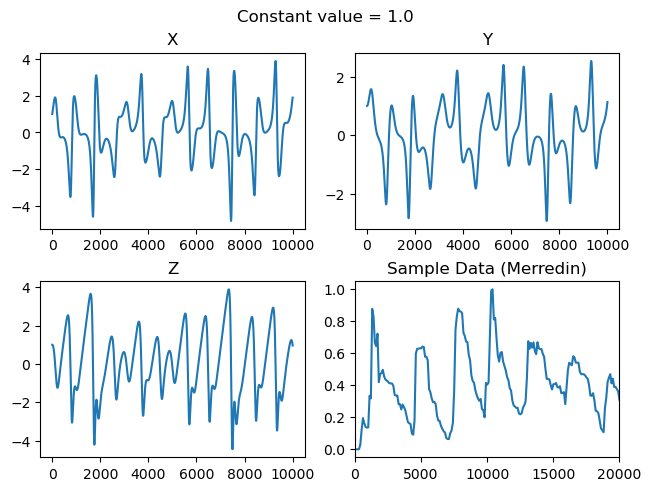

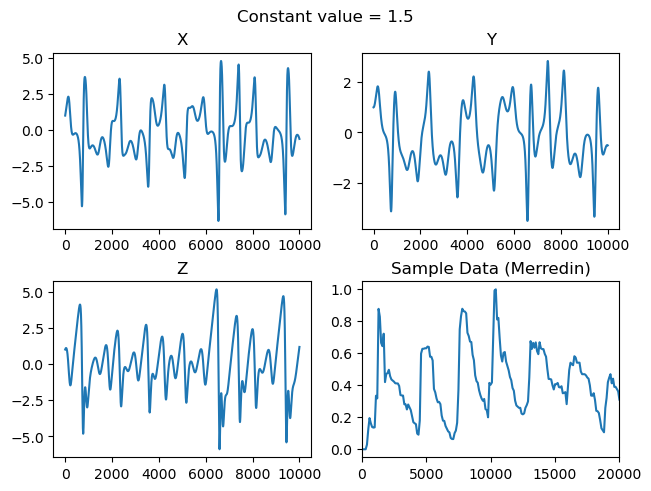

In [9]:
# varing the constant value for dzdt

for i in np.arange(0.5,2, 0.5):
    vals = rk4_sprott(x0=1, y0=1, z0=1,t0=0, tf=100,h=0.01, coef=1, constant=i)
    x,y,z = vals.T
    fig, axs = plt.subplots(2,2, layout="constrained")
    fig.suptitle(f"Constant value = {i}")
    axs[0,0].plot(x)
    axs[0,0].set_title('X')
    axs[0,1].plot(y)
    axs[0,1].set_title('Y')
    axs[1,0].plot(z)
    axs[1,0].set_title('Z')
    axs[1,1].plot(merre_gddc, merre_rain)
    axs[1,1].set_xlim([0,20000])
    axs[1,1].set_title('Sample Data (Merredin)')

# larger constant values correspond to higher frequency of oscillations/shorter period


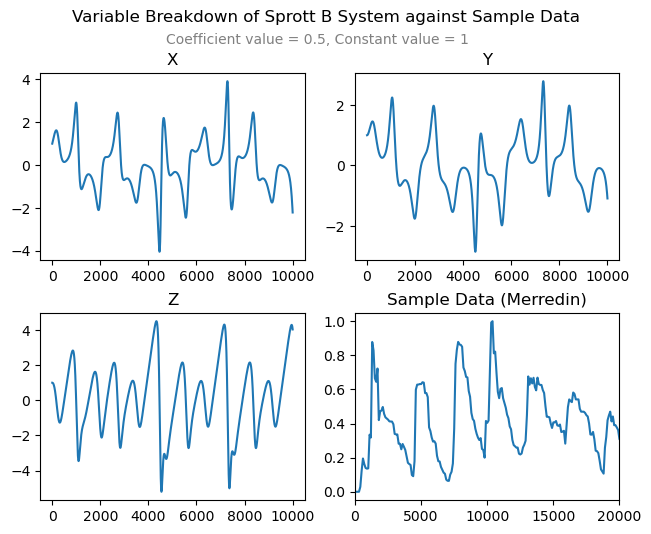

In [10]:

# chosen parameters are a coefficient of 0.5 and a constant of 1
vals = rk4_sprott(x0=1, y0=1, z0=1,t0=0, tf=100,h=0.01, coef=0.5, constant=1)
x,y,z = vals.T
fig, axs = plt.subplots(2,2, layout="constrained")
fig.suptitle('Variable Breakdown of Sprott B System against Sample Data', y=1.08)
fig.text(0.25, 1.01, "Coefficient value = 0.5, Constant value = 1", color = "grey")
axs[0,0].plot(x)
axs[0,0].set_title('X')
axs[0,1].plot(y)
axs[0,1].set_title('Y')
axs[1,0].plot(z)
axs[1,0].set_title('Z')
axs[1,1].plot(merre_gddc, merre_rain)
axs[1,1].set_xlim([0,20000])
axs[1,1].set_title('Sample Data (Merredin)')
plt.savefig('SprottBParams.png', bbox_inches='tight')
plt.show()

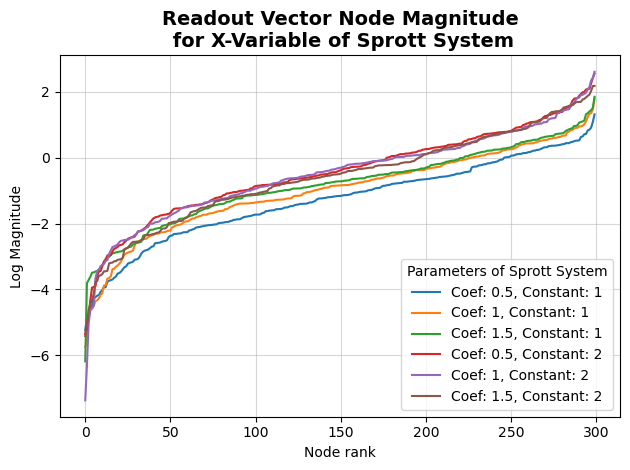

In [13]:

# plotting resulting complexity curves depending on parameters onto the same plot 
def varyparams_complexity_sprott(esn, x0, y0, z0,t0, tf,h, coefs, constants):
    x_nodes = {}
    for constant in constants:
        for coef in coefs:
            vals = rk4_sprott(x0, y0, z0,t0, tf,h, coef=coef, constant=constant)
            x_vals = vals[:,0]

            x_rmse, x_vout = calculate_metrics(esn, 'Sprott Attractor X', x_vals, np.arange(len(x_vals)), step=10)
            x_area = trapezoid(np.abs(x_vout))

            x_nodes[f'Coef: {coef}, Constant: {constant}'] = np.log(np.sort(np.abs(x_vout)))

    return x_nodes

x_nodes = varyparams_complexity_sprott(esn, x0=1, y0=1, z0=1,t0=0, tf=100,h=0.01, coefs=(0.5,1,1.5), constants=(1,2))
for parameters, nodes in x_nodes.items():
    plt.plot(nodes, label = f'{parameters}')
plt.grid(alpha=0.5)
plt.legend(title = "Parameters of Sprott System")
plt.title('Readout Vector Node Magnitude\n for X-Variable of Sprott System', size=14, fontweight="bold")
plt.ylabel('Log Magnitude')
plt.xlabel('Node rank')
plt.tight_layout()
plt.savefig('SprottParams_Complexity.png')
plt.show()

#increasing the value of the constant, increases AUC for all variables => more nodes used



RMSE of Variable Z - Step: 1 Prediction: 0.0005297949702978409
RMSE of Variable Z - Step: 2 Prediction: 0.0010322605194746815
RMSE of Variable Z - Step: 5 Prediction: 0.0026659724416117597
RMSE of Variable Z - Step: 10 Prediction: 0.005845764147342931
RMSE of Variable Z - Step: 20 Prediction: 0.014146698350835207
RMSE of Variable Z - Step: 50 Prediction: 0.0533659516658845
RMSE of Variable Z - Step: 95 Prediction: 0.18225125908730105
RMSE of Variable Z - Step: 96 Prediction: 0.18662357239741256
RMSE of Variable Z - Step: 97 Prediction: 0.1910726986972789
RMSE of Variable Z - Step: 100 Prediction: 0.20488737215519176


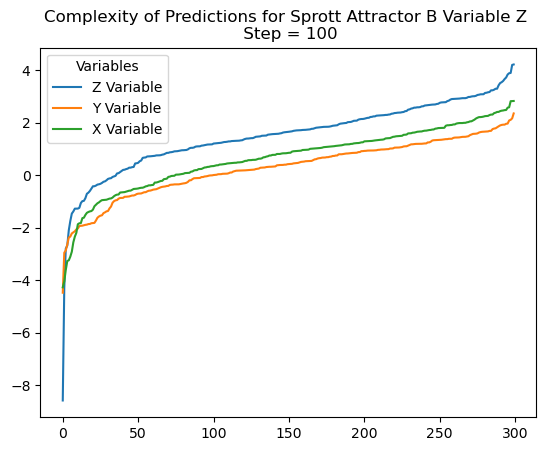

In [12]:
# calculating how complexity changes for Sprott system depending on step size 
def sprott_changestep(esn, x0, y0, z0,t0, tf,h, coef, constant, steps):
    for step in steps:
        vals = rk4_sprott(x0, y0, z0,t0, tf,h, coef=coef, constant=constant)
        x_vals = vals[:,0]
        y_vals = vals[:,1]
        z_vals = vals[:,2]

        z_rmse, z_vout = calculate_metrics(esn, 'Sprott Attractor Z', z_vals, np.arange(len(z_vals)), step=step)
        _, x_vout = calculate_metrics(esn, 'Sprott Attractor X', x_vals, np.arange(len(x_vals)), step=step)
        _, y_vout = calculate_metrics(esn, 'Sprott Attractor Y', y_vals, np.arange(len(y_vals)), step=step)


        z_area = trapezoid(np.log(np.abs(z_vout)))

        print("RMSE of Variable Z - Step:", str(step), "Prediction: " + str(z_rmse))

        z_nodes = np.log(np.sort(np.abs(z_vout)))
        y_nodes = np.log(np.sort(np.abs(y_vout)))
        x_nodes = np.log(np.sort(np.abs(x_vout)))


        if step == 100:
            plt.plot(z_nodes, label = 'Z Variable')
            plt.plot(y_nodes, label = 'Y Variable')
            plt.plot(x_nodes, label = 'X Variable')
            plt.title("Complexity of Predictions for Sprott Attractor B Variable Z \n Step = " + str(step))
            plt.legend(title = 'Variables')
            plt.show()

sprott_changestep(esn, x0=1, y0=1, z0=1,t0=0, tf=100,h=0.01, coef=0.5, constant=1, steps=(1, 2, 5, 10, 20,50, 95, 96, 97, 100))

